# 2. Binomial tree and Greeks

The binomial tree is the simplest numerical method, and the first one that can handle **American** options (early exercise). This notebook also computes the **Greeks**, the sensitivities used for hedging, in three different ways.

In [1]:
import sys
sys.path.insert(0, "..")  # make the `pricer` package importable from the notebooks folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pricer import VanillaOption, black_scholes, monte_carlo, binomial, finite_difference, exotics
from pricer.greeks import bump_greeks
from pricer.plotting import use_style, BLUE, ORANGE, AQUA, YELLOW, MUTED, INK_SOFT

use_style()
pd.options.display.float_format = "{:.4f}".format

# Reference contract used throughout: an at-the-money one-year option.
call = VanillaOption(spot=100, strike=100, maturity=1.0, rate=0.05, vol=0.2, option_type="call")
put = call.with_(option_type="put")

## 2.1 Convergence of the tree

Over a step $\Delta t$ the price is multiplied by $u = e^{\sigma\sqrt{\Delta t}}$ or $d = 1/u$, with risk-neutral probability $p = \dfrac{e^{(r-q)\Delta t} - d}{u - d}$ of going up. The option value is rolled back from expiry:

$$V = e^{-r\Delta t}\,[\,p\,V_{\text{up}} + (1-p)\,V_{\text{down}}\,].$$

The price converges to Black-Scholes, but not monotonically: it oscillates because the position of the strike relative to the tree nodes changes with the number of steps.

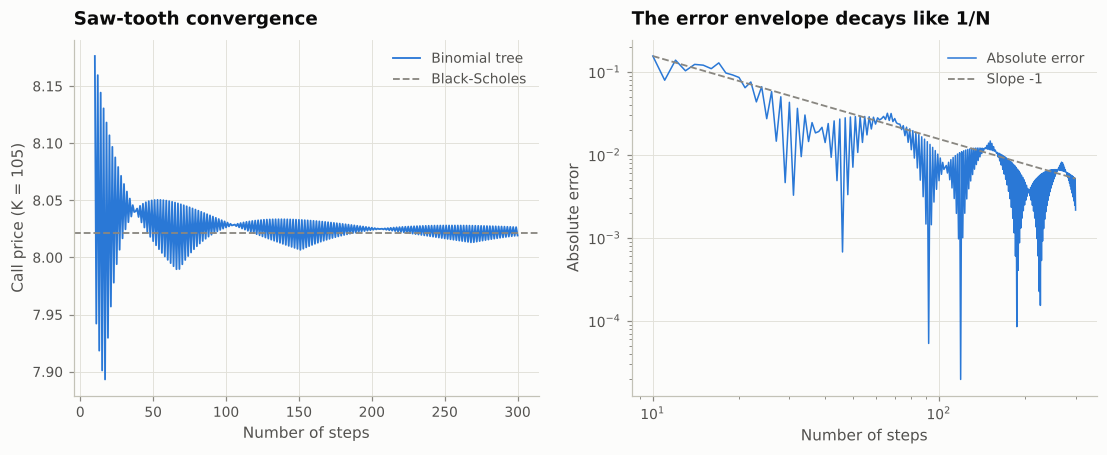

In [2]:
option = call.with_(strike=105)
exact = black_scholes.price(option)
steps = np.arange(10, 301)
prices = np.array([binomial.price(option, int(n)) for n in steps])

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
left.plot(steps, prices, color=BLUE, linewidth=1.2, label="Binomial tree")
left.axhline(exact, color=MUTED, linestyle="--", linewidth=1.2, label="Black-Scholes")
left.set_xlabel("Number of steps"); left.set_ylabel("Call price (K = 105)")
left.set_title("Saw-tooth convergence"); left.legend()

right.loglog(steps, np.abs(prices - exact), color=BLUE, linewidth=1.0, label="Absolute error")
right.loglog(steps, np.abs(prices[0] - exact) * steps[0] / steps, color=MUTED, linestyle="--", linewidth=1.2,
             label="Slope -1")
right.set_xlabel("Number of steps"); right.set_ylabel("Absolute error")
right.set_title("The error envelope decays like 1/N"); right.legend();

## 2.2 American options

At each node the holder compares the value of exercising now with the value of waiting, and keeps the larger. Two classical results can be checked:

* an American **call** on a stock without dividends is never exercised early, so it is worth exactly the European call;
* an American **put** is worth strictly more than the European put.

In [3]:
rows = []
for name, option in [("Call, no dividend", call), ("Put, no dividend", put),
                     ("Call, 6% dividend", call.with_(dividend_yield=0.06))]:
    european = binomial.price(option, 1000)
    american = binomial.price(option, 1000, american=True)
    rows.append({"Contract": name, "European": european, "American": american,
                 "Early-exercise premium": american - european})
pd.DataFrame(rows).set_index("Contract")

,European,American,Early-exercise premium
Contract,,,
"Call, no dividend",10.4486,10.4486,0.0000
"Put, no dividend",5.5715,6.0896,0.5181
"Call, 6% dividend",7.0736,7.2554,0.1818


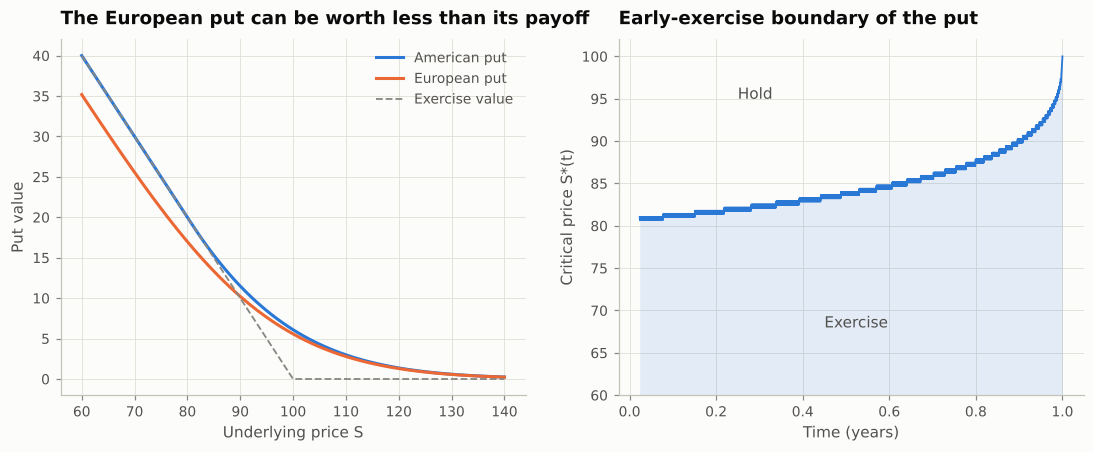

In [4]:
spots = np.linspace(60, 140, 81)
european = [black_scholes.price(put.with_(spot=s)) for s in spots]
american = [binomial.price(put.with_(spot=s), 500, american=True) for s in spots]
times, boundary = binomial.early_exercise_boundary(put, 2000)
known = ~np.isnan(boundary)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
left.plot(spots, american, color=BLUE, label="American put")
left.plot(spots, european, color=ORANGE, label="European put")
left.plot(spots, put.payoff(spots), color=MUTED, linestyle="--", linewidth=1.2, label="Exercise value")
left.set_xlabel("Underlying price S"); left.set_ylabel("Put value")
left.set_title("The European put can be worth less than its payoff"); left.legend()

right.plot(times[known], boundary[known], color=BLUE, linewidth=1.2)
right.fill_between(times[known], 60, boundary[known], color=BLUE, alpha=0.12, linewidth=0)
right.text(0.45, 68, "Exercise", color=INK_SOFT); right.text(0.25, 95, "Hold", color=INK_SOFT)
right.set_ylim(60, 102); right.set_xlabel("Time (years)"); right.set_ylabel("Critical price S*(t)")
right.set_title("Early-exercise boundary of the put");

## 2.3 Greeks

| Greek | Definition | Meaning |
|---|---|---|
| Delta | $\partial V/\partial S$ | exposure to the underlying, also the hedge ratio |
| Gamma | $\partial^2 V/\partial S^2$ | how fast the hedge must be adjusted |
| Vega | $\partial V/\partial\sigma$ | exposure to volatility |
| Theta | $\partial V/\partial t$ | value lost as time passes |
| Rho | $\partial V/\partial r$ | exposure to interest rates |

Three independent computations of the same numbers:

1. **closed-form** formulas;
2. **bump and revalue**: reprice with a slightly shifted input and take a finite difference (works with any pricer);
3. **inside Monte Carlo**: pathwise and likelihood-ratio estimators.

In [5]:
table = pd.DataFrame({
    "Closed form": black_scholes.greeks(call),
    "Bump: Black-Scholes": bump_greeks(black_scholes.price, call),
    "Bump: binomial tree": bump_greeks(lambda o: binomial.price(o, 2000), call),
    "Bump: finite differences": bump_greeks(lambda o: finite_difference.price(o, n_space=800, n_time=800), call),
})
table

,Closed form,Bump: Black-Scholes,Bump: binomial tree,Bump: finite differences
delta,0.6368,0.6367,0.6367,0.6368
gamma,0.0188,0.0188,0.0203,0.0188
vega,37.5240,37.5240,37.5193,37.5274
theta,-6.4140,-6.4169,-6.4164,-6.4172
rho,53.2325,53.2325,53.2319,53.2321


In [6]:
n = 400_000
estimators = {
    "Delta, pathwise": (monte_carlo.delta_pathwise(call, n, seed=1), black_scholes.delta(call)),
    "Delta, likelihood ratio": (monte_carlo.delta_likelihood_ratio(call, n, seed=1), black_scholes.delta(call)),
    "Vega, pathwise": (monte_carlo.vega_pathwise(call, n, seed=1), black_scholes.vega(call)),
}
pd.DataFrame(
    [{"Estimator": name, "Estimate": r.price, "Std error": r.std_error, "Exact": exact_value}
     for name, (r, exact_value) in estimators.items()]
).set_index("Estimator")

,Estimate,Std error,Exact
Estimator,,,
"Delta, pathwise",0.6359,0.0009,0.6368
"Delta, likelihood ratio",0.6310,0.0023,0.6368
"Vega, pathwise",37.1891,0.1192,37.5240


The pathwise estimator is more precise here. The likelihood-ratio estimator is noisier, but it does not need the payoff to be differentiable, which makes it the method of choice for digital options.

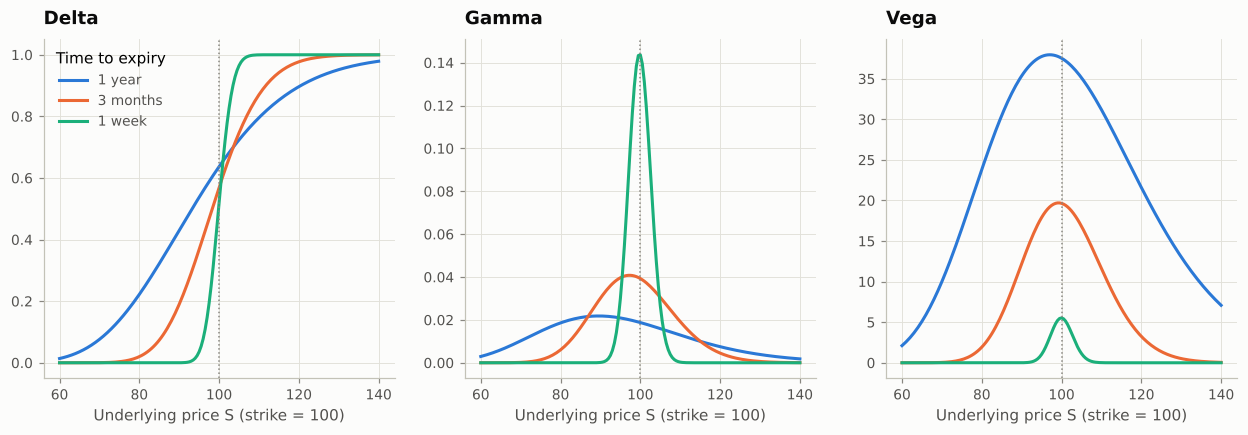

In [7]:
spots = np.linspace(60, 140, 161)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))
for maturity, color, label in [(1.0, BLUE, "1 year"), (0.25, ORANGE, "3 months"), (1 / 52, AQUA, "1 week")]:
    options = [call.with_(spot=s, maturity=maturity) for s in spots]
    axes[0].plot(spots, [black_scholes.delta(o) for o in options], color=color, label=label)
    axes[1].plot(spots, [black_scholes.gamma(o) for o in options], color=color, label=label)
    axes[2].plot(spots, [black_scholes.vega(o) for o in options], color=color, label=label)
for ax, name in zip(axes, ["Delta", "Gamma", "Vega"]):
    ax.axvline(call.strike, color=MUTED, linestyle=":", linewidth=1.0)
    ax.set_title(name); ax.set_xlabel("Underlying price S (strike = 100)")
axes[0].legend(title="Time to expiry");

Near expiry the delta of an at-the-money option jumps from 0 to 1 over a narrow range of prices and gamma becomes very large: this is why short-dated at-the-money options are the hardest to hedge.

## Summary

* The tree converges to Black-Scholes at rate $1/N$ with a saw-tooth pattern.
* It prices American options and gives the early-exercise boundary.
* Analytic, bump-and-revalue and Monte Carlo Greeks all agree.